# Notebook 4 — Regressão Logística do Zero

### Sigmoide, entropia cruzada e gradiente descendente

**Disciplina:** IBM3116 — Métodos e Aplicações de IA · Engenharia de Software  
**Professor:** Carlos Eduardo Leal de Castro  
**Modalidade:** Estudo Dirigido  
**Entrega 3:** até **18/09/2026** 

---

Este notebook apresenta o núcleo da regressão logística e termina com **três exercícios**. Execute as
células na ordem (`Kernel → Restart & Run All`). As células marcadas com `# TODO` são destinadas à sua
resposta e não interrompem a execução do restante do material.

## 1. Por que estudar regressão logística?

Considere um sistema de manutenção preditiva. Para cada motor, conhecemos a **temperatura** e a
**vibração** medidas no fim do turno. Precisamos decidir se o equipamento deve ser inspecionado:

- `0`: operação normal;
- `1`: risco de falha nas próximas 24 horas.

Na aula anterior, a regressão linear produzia qualquer valor real. Aqui isso não basta: uma saída
como `1,37` não é uma probabilidade válida, e escolher diretamente uma classe não expressa a
incerteza da decisão.

A regressão logística resolve o problema em duas etapas:

$$
\mathbf{x}\longrightarrow z=\mathbf{x}^{\top}\boldsymbol\beta
\longrightarrow p=\sigma(z)\longrightarrow \hat y.
$$

Primeiro calcula um **escore linear** $z$; depois o transforma em uma probabilidade $p\in(0,1)$
com a função sigmoide. A classe final depende de um **limiar de decisão**, que pode ser ajustado ao
custo real de falsos positivos e falsos negativos.

## 2. Pré-requisitos e notação

Para $n$ observações e $p$ atributos:

- $\mathbf X\in\mathbb R^{n\times p}$: matriz de atributos;
- $\mathbf y\in\{0,1\}^{n}$: vetor de rótulos;
- $\tilde{\mathbf X}=[\mathbf 1\;\mathbf X]$: matriz com coluna de *bias*;
- $\boldsymbol\beta\in\mathbb R^{p+1}$: intercepto e coeficientes;
- $\mathbf z=\tilde{\mathbf X}\boldsymbol\beta$: escores lineares;
- $\mathbf p=\sigma(\mathbf z)$: probabilidades previstas.

O produto matriz-vetor produz todos os escores sem um laço explícito sobre as observações.

## 3. Ambiente e reprodutibilidade

Use o ambiente `MAIA` configurado no primeiro notebook. Este material requer NumPy, pandas,
Matplotlib e scikit-learn. Todas as fontes de aleatoriedade recebem uma semente explícita.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

SEED = 42
np.set_printoptions(precision=4, suppress=True)
plt.style.use("seaborn-v0_8-whitegrid")

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

Python: 3.11.15
NumPy: 2.4.6
pandas: 3.0.5


## 4. O problema em dados

Geraremos uma base sintética de motores. A classe não será determinada por uma regra perfeita:
dois motores com as mesmas medições podem ter destinos diferentes. Essa incerteza é realista e
torna a saída probabilística útil.

Os atributos disponíveis no momento da decisão são:

- temperatura do mancal, em °C;
- vibração RMS, em mm/s.

O processo gerador abaixo é conhecido apenas porque estamos construindo um laboratório. Em um
problema real, os coeficientes são desconhecidos e precisam ser aprendidos a partir dos dados.

In [2]:
def gerar_motores(n=900, seed=SEED):
    rng = np.random.default_rng(seed)
    temperatura = rng.normal(68.0, 8.0, n)
    vibracao = rng.gamma(shape=2.2, scale=0.9, size=n) + 0.25

    # Relação probabilística usada apenas para gerar os rótulos.
    z_real = -1.15 + 0.095 * (temperatura - 68.0) + 0.95 * (vibracao - 2.0)
    p_real = 1.0 / (1.0 + np.exp(-z_real))
    falha = rng.binomial(1, p_real)

    X = np.column_stack([temperatura, vibracao])
    return X, falha.astype(int), p_real


X, y, p_real = gerar_motores()
nomes = np.array(["temperatura_C", "vibracao_mm_s"])

dados = pd.DataFrame(X, columns=nomes)
dados["falha_24h"] = y
print(dados.head())
print("\nDimensões:", X.shape)
print("Prevalência de falha:", y.mean().round(3))

   temperatura_C  vibracao_mm_s  falha_24h
0      70.437737       2.456180          0
1      59.680127       1.755143          0
2      74.003610       1.275178          1
3      75.524518       1.667768          1
4      52.391718       2.017450          0

Dimensões: (900, 2)
Prevalência de falha: 0.323


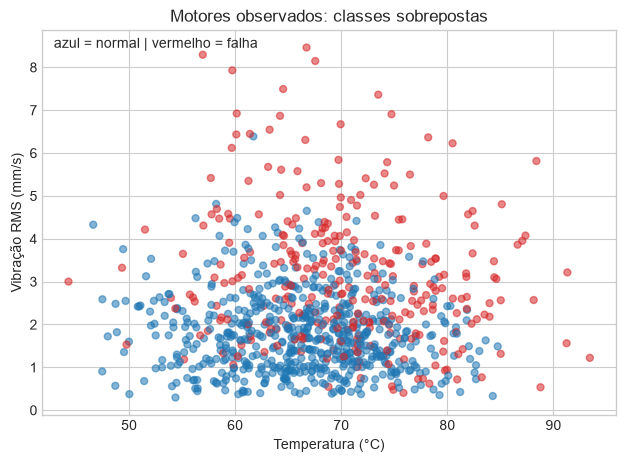

In [3]:
fig, ax = plt.subplots(figsize=(7.4, 5.0))
cores = np.where(y == 1, "tab:red", "tab:blue")
ax.scatter(X[:, 0], X[:, 1], c=cores, alpha=0.55, s=25)
ax.set(xlabel="Temperatura (°C)", ylabel="Vibração RMS (mm/s)",
       title="Motores observados: classes sobrepostas")
ax.text(0.02, 0.98, "azul = normal | vermelho = falha",
        transform=ax.transAxes, va="top")
plt.show()

## 5. Do escore linear à probabilidade

Assim como na regressão linear, calculamos

$$z_i=\beta_0+\beta_1x_{i1}+\cdots+\beta_px_{ip}.$$

O escore $z$ pode assumir qualquer valor real. Valores positivos serão evidência a favor da classe
1; valores negativos, evidência a favor da classe 0. Falta transformá-lo em uma quantidade entre
zero e um.

In [17]:
def add_bias(X):
    X = np.asarray(X, dtype=float)
    return np.column_stack([np.ones(X.shape[0]), X])


def linear_score(X_tilde, beta):
    return X_tilde @ beta


X_tilde = add_bias(X)
beta_exemplo = np.array([-2.0, 0.02, 0.8])
print("Formato de X com bias:", X_tilde.shape)
print("Primeiros escores:", linear_score(X_tilde, beta_exemplo)[:5])

Formato de X com bias: (900, 3)
Primeiros escores: [1.3737 0.5977 0.5002 0.8447 0.6618]


## 6. A função sigmoide

A função logística, ou sigmoide, é

$$\sigma(z)=\frac{1}{1+e^{-z}}.$$

Propriedades importantes:

- $\sigma(0)=0{,}5$;
- $z\to+\infty\Rightarrow\sigma(z)\to1$;
- $z\to-\infty\Rightarrow\sigma(z)\to0$;
- $\sigma'(z)=\sigma(z)[1-\sigma(z)]$.

A última identidade será decisiva na derivação do gradiente.

[[-1000.        0.   ]
 [   -4.        0.018]
 [    0.        0.5  ]
 [    4.        0.982]
 [ 1000.        1.   ]]


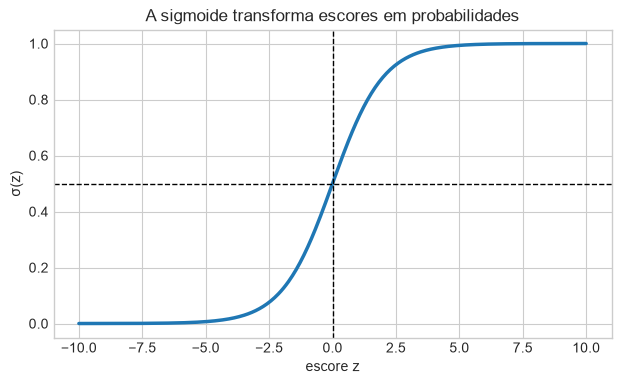

In [18]:
def sigmoid(z):
    # Sigmoide vetorizada com proteção contra overflow numérico.
    z = np.asarray(z, dtype=float)
    z_seguro = np.clip(z, -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-z_seguro))


z_grade = np.linspace(-10, 10, 400)
valores_teste = np.array([-1000, -4, 0, 4, 1000], dtype=float)
print(np.column_stack([valores_teste, sigmoid(valores_teste)]))

plt.figure(figsize=(7.2, 4.0))
plt.plot(z_grade, sigmoid(z_grade), linewidth=2.5)
plt.axhline(0.5, color="black", linestyle="--", linewidth=1)
plt.axvline(0.0, color="black", linestyle="--", linewidth=1)
plt.xlabel("escore z")
plt.ylabel("σ(z)")
plt.title("A sigmoide transforma escores em probabilidades")
plt.show()

## Exercício 1 — Sigmoide e probabilidade

Para os escores $[-3,0,1,4]$:

1. calcule as probabilidades com `sigmoid`;
2. identifique quais casos seriam classificados como 1 com limiar $0{,}5$;
3. explique, em até quatro linhas, por que dobrar o escore não dobra a probabilidade.

**Entregável:** código e resposta curta em Markdown.

In [ ]:
# =============================================================================
# ✅ RESPOSTA — EXERCÍCIO 1 · itens 1 e 2
# =============================================================================
escores = np.array([-3.0, 0.0, 1.0, 4.0])
probabilidades = sigmoid(escores)

LIMIAR = 0.5
classes = (probabilidades >= LIMIAR).astype(int)      # mesma convenção de predict_class

tabela_ex1 = pd.DataFrame({
    "z": escores,
    "sigma(z)": probabilidades.round(6),
    "odds = e^z": np.exp(escores).round(4),
    "classe (p >= 0,5)": classes,
})
print(tabela_ex1.to_string(index=False))
print("\nClassificados como 1 (limiar 0,5):", escores[classes == 1])
print("Atenção: z = 0 dá p = 0,5 exatamente — fica em cima do limiar.")
print("  com a convenção p >= 0,5 (a do notebook):", (probabilidades >= 0.5).astype(int))
print("  com a convenção p >  0,5              :", (probabilidades > 0.5).astype(int))

# -----------------------------------------------------------------------------
# Item 3 — evidência numérica: dobrar z não dobra p; dobrar z ELEVA AO QUADRADO as odds
# -----------------------------------------------------------------------------
print("\n" + "-" * 52)
print(f"{'z':>5} {'sigma(z)':>12} {'odds = e^z':>12}")
for z in [0.5, 1.0, 2.0, 4.0, 8.0]:
    print(f"{z:5.1f} {sigmoid(z):12.6f} {np.exp(z):12.4f}")

print(f"\nDobrando z de 1 para 2:")
print(f"   p    : {sigmoid(1.0):.6f} -> {sigmoid(2.0):.6f}   (x{sigmoid(2.0) / sigmoid(1.0):.3f}, longe de dobrar)")
print(f"   odds : {np.exp(1.0):.6f} -> {np.exp(2.0):.6f}   (= {np.exp(1.0):.4f}², ou seja, ao quadrado)")
print(f"Dobrando z de 4 para 8:")
print(f"   p    : {sigmoid(4.0):.6f} -> {sigmoid(8.0):.6f}   (x{sigmoid(8.0) / sigmoid(4.0):.3f}: quase nada)")
print(f"   odds : {np.exp(4.0):.2f} -> {np.exp(8.0):.2f}")

print(f"\nInclinação máxima da sigmoide (em z=0): sigma'(0) = 0,25")
print("Longe de zero a curva satura: p é limitado a (0,1), as odds não são.")

---

## ✅ RESPOSTA — Exercício 1 (Sigmoide e probabilidade)

> Itens 1 e 2 calculados na célula acima; item 3 respondido abaixo, em quatro linhas, como pedido.

**1. Probabilidades para os escores $[-3,\,0,\,1,\,4]$:**

| $z$ | $\sigma(z)$ | odds $= e^{z}$ | classe com $t = 0{,}5$ |
|--:|--:|--:|:--:|
| $-3$ | 0,047426 | 0,0498 | **0** |
| $0$ | 0,500000 | 1,0000 | **1** (ver nota) |
| $1$ | 0,731059 | 2,7183 | **1** |
| $4$ | 0,982014 | 54,5982 | **1** |

**2. Classificados como 1 com limiar 0,5:** os escores $z = 0$, $z = 1$ e $z = 4$.

> **Nota sobre o empate.** $z = 0$ produz $p = 0{,}5$ **exatamente**, em cima do limiar. A função `predict_class` do notebook usa `p >= threshold`, então esse caso vai para a classe 1; com a convenção `p > threshold` iria para a classe 0. O caso de borda não é decidido pela matemática, e sim pela convenção de código — vale documentá-la.

**3. Por que dobrar o escore não dobra a probabilidade** (quatro linhas):

1. A sigmoide é **não linear e saturante**: $p$ é limitado ao intervalo $(0,1)$, então nenhuma quantidade de escore pode dobrar uma probabilidade que já vale 0,73.
2. O que é linear em $z$ não é $p$, e sim o **logito**: $z = \log\frac{p}{1-p}$; logo dobrar $z$ dobra o log das odds, o que equivale a **elevar as odds ao quadrado** — de fato, $\text{odds}(2z) = (e^{z})^{2} = \text{odds}(z)^{2}$.
3. Numericamente: $z: 1 \to 2$ leva $p$ de 0,7311 para 0,8808 (apenas $\times 1{,}20$), enquanto as odds vão de 2,7183 para $7{,}3891 = 2{,}7183^{2}$.
4. O efeito depende de **onde** se está na curva: a inclinação é máxima em $z = 0$ ($\sigma'(0) = 0{,}25$) e tende a zero nas caudas — por isso $z: 4 \to 8$ muda $p$ de 0,9820 para 0,9997, praticamente nada.

**Consequência prática:** um coeficiente $\beta_j$ da regressão logística **não** diz "quanto a probabilidade sobe por unidade de $x_j$" — esse efeito varia ao longo da curva. Ele diz que as odds são multiplicadas por $e^{\beta_j}$ a cada unidade de $x_j$, e essa leitura vale em qualquer ponto.

---

## 7. Por que não usar o erro quadrático?

Poderíamos aplicar MSE às probabilidades, mas ele não corresponde à distribuição probabilística
natural de um rótulo binário e produz uma geometria menos conveniente para otimização.

Se $y\in\{0,1\}$ e o modelo prevê $p$, a probabilidade atribuída ao evento observado é

$$P(y\mid p)=p^y(1-p)^{1-y}.$$

Maximizar a probabilidade conjunta dos dados equivale a minimizar a **entropia cruzada binária**:

$$
J(\boldsymbol\beta)=-\frac1n\sum_{i=1}^{n}
\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right].
$$

Uma previsão confiante e errada recebe penalidade muito alta. Uma previsão confiante e correta
recebe custo próximo de zero.

In [7]:
def binary_cross_entropy(y_true, p_pred, eps=1e-15):
    y_true = np.asarray(y_true, dtype=float)
    p_pred = np.clip(np.asarray(p_pred, dtype=float), eps, 1.0 - eps)
    return -np.mean(y_true * np.log(p_pred) + (1.0 - y_true) * np.log(1.0 - p_pred))


casos = pd.DataFrame({
    "y": [1, 1, 1, 0, 0, 0],
    "p": [0.99, 0.70, 0.10, 0.01, 0.30, 0.90],
})
casos["perda_individual"] = -(
    casos["y"] * np.log(casos["p"])
    + (1 - casos["y"]) * np.log(1 - casos["p"])
)
print(casos.round(4))

   y     p  perda_individual
0  1  0.99            0.0101
1  1  0.70            0.3567
2  1  0.10            2.3026
3  0  0.01            0.0101
4  0  0.30            0.3567
5  0  0.90            2.3026


## Exercício 2 — Entropia cruzada

Um modelo produziu probabilidades $[0{,}8,0{,}4,0{,}1]$ para rótulos $[1,1,0]$.

1. calcule a entropia cruzada média;
2. troque a segunda probabilidade por $0{,}01$ e recalcule;
3. explique por que uma previsão confiante e errada recebe penalidade alta.

**Entregável:** cálculo, verificação em NumPy e interpretação curta.

In [ ]:
# =============================================================================
# ✅ RESPOSTA — EXERCÍCIO 2 · itens 1 e 2
# =============================================================================
y_ex2 = np.array([1, 1, 0])
p_ex2 = np.array([0.8, 0.4, 0.1])          # cenário original
p_ex2_alt = np.array([0.8, 0.01, 0.1])     # segunda probabilidade trocada por 0,01


def detalhar(y_true, p_pred, rotulo):
    """Mostra a perda de cada observação e a média (entropia cruzada)."""
    perdas = -(y_true * np.log(p_pred) + (1 - y_true) * np.log(1 - p_pred))
    tabela = pd.DataFrame({
        "y": y_true,
        "p": p_pred,
        "prob. dada ao evento observado": np.where(y_true == 1, p_pred, 1 - p_pred),
        "perda = -log(...)": perdas.round(6),
    })
    print(f"--- {rotulo} ---")
    print(tabela.to_string(index=False))
    print(f"soma = {perdas.sum():.6f}   |   média (BCE) = {perdas.mean():.6f}")
    print(f"conferindo com binary_cross_entropy: {binary_cross_entropy(y_true, p_pred):.6f}\n")
    return perdas.mean()


bce_original = detalhar(y_ex2, p_ex2, "1) original: p = [0,8 | 0,4 | 0,1]")
bce_alterada = detalhar(y_ex2, p_ex2_alt, "2) alterado: p = [0,8 | 0,01 | 0,1]")

print("=" * 62)
print(f"BCE original : {bce_original:.6f}   (conta à mão: 1,244795 / 3)")
print(f"BCE alterada : {bce_alterada:.6f}   (conta à mão: 4,933674 / 3)")
print(f"aumento      : {bce_alterada - bce_original:+.6f}  ->  {bce_alterada / bce_original:.2f}x maior")
print(f"\nA observação culpada é a 2ª: sua perda vai de {-np.log(0.4):.6f} para {-np.log(0.01):.6f} "
      f"({np.log(0.01) / np.log(0.4):.2f}x)")
print("As outras duas observações não mudaram: uma única previsão quadruplicou o custo do modelo.")

# Item 3 — a penalidade é ILIMITADA quando a previsão confiante está errada.
print("\n" + "-" * 62)
print(f"{'p atribuído à classe certa':>28} {'perda = -ln(p)':>16}")
for p in [0.9, 0.5, 0.1, 0.01, 1e-3, 1e-6, 1e-12]:
    print(f"{p:>28g} {-np.log(p):16.4f}")
print("\n-log(p) -> +infinito quando p -> 0: não existe teto para o custo de estar")
print("confiantemente errado. É por isso que binary_cross_entropy limita p a [1e-15, 1-1e-15]:")
print(f"sem esse clip, p = 0 exato daria log(0) = -inf. Com o clip, a perda máxima é {-np.log(1e-15):.4f}.")

plt.figure(figsize=(7.2, 4.0))
grade_p = np.linspace(0.001, 0.999, 500)
plt.plot(grade_p, -np.log(grade_p), label="perda quando y = 1")
plt.plot(grade_p, -np.log(1 - grade_p), label="perda quando y = 0")
plt.scatter([0.4, 0.01], [-np.log(0.4), -np.log(0.01)], color="tab:red", zorder=5, s=55)
plt.annotate("p=0,4", (0.4, -np.log(0.4)), textcoords="offset points", xytext=(8, 6))
plt.annotate("p=0,01", (0.01, -np.log(0.01)), textcoords="offset points", xytext=(10, -4))
plt.ylim(0, 7); plt.xlabel("probabilidade prevista p"); plt.ylabel("perda individual")
plt.title("A entropia cruzada explode quando a previsão confiante está errada")
plt.legend(); plt.show()

---

## ✅ RESPOSTA — Exercício 2 (Entropia cruzada)

> Cálculo à mão abaixo; verificação em NumPy na célula acima; interpretação no item 3.

**1. Entropia cruzada média do cenário original** — rótulos $y = [1,\,1,\,0]$ e probabilidades $p = [0{,}8;\ 0{,}4;\ 0{,}1]$.

A perda de cada observação é $-\log$ da probabilidade que o modelo atribuiu ao **evento que de fato ocorreu**:

| $i$ | $y_i$ | $p_i$ | prob. do evento observado | perda $\ell_i$ |
|:--:|:--:|--:|--:|--:|
| 1 | 1 | 0,80 | $p_1 = 0{,}80$ | $-\ln 0{,}80 = 0{,}223144$ |
| 2 | 1 | 0,40 | $p_2 = 0{,}40$ | $-\ln 0{,}40 = 0{,}916291$ |
| 3 | 0 | 0,10 | $1-p_3 = 0{,}90$ | $-\ln 0{,}90 = 0{,}105361$ |
| | | | **soma** | **1,244795** |

$$J = \frac{1{,}244795}{3} = \boxed{0{,}414932}$$

**2. Trocando a segunda probabilidade por $0{,}01$** — só a linha 2 muda, porque a perda é calculada observação a observação:

$$-\ln 0{,}01 = 4{,}605170 \quad\text{(era } 0{,}916291\text{)}$$

$$J' = \frac{0{,}223144 + 4{,}605170 + 0{,}105361}{3} = \frac{4{,}933674}{3} = \boxed{1{,}644558}$$

O custo do modelo **quase quadruplicou** ($\times 3{,}96$) por causa de **uma única** previsão entre três. A perda daquela observação isolada ficou 5,03 vezes maior.

**3. Por que uma previsão confiante e errada recebe penalidade alta.**

A penalidade é $-\log(p_{\text{evento observado}})$, e essa função **diverge para o infinito** quando $p \to 0$:

| $p$ dado à classe certa | 0,90 | 0,50 | 0,10 | 0,01 | $10^{-6}$ | $10^{-12}$ |
|:--|--:|--:|--:|--:|--:|--:|
| perda $-\ln p$ | 0,105 | 0,693 | 2,303 | 4,605 | 13,816 | 27,631 |

Dizer "$p = 0{,}01$" quando o evento ocorre não é um erro pequeno: é afirmar que aquilo aconteceria **1 vez em 100**, e estar errado. Errar com $p=0{,}4$ é apenas hesitar; errar com $p=0{,}01$ é apostar alto contra o resultado. A entropia cruzada cobra essa diferença — o que a torna uma perda que exige **calibração**, e não só acerto na classe: um modelo que acerta o lado do limiar mas grita com confiança indevida é punido. Note o contraste com a perda 0–1, que daria erro 1 nos dois casos, e com o MSE, cuja penalidade máxima é limitada a 1.

**Por isso existe o `eps = 1e-15` em `binary_cross_entropy`.** Sem ele, uma previsão de exatamente $p = 0$ para um caso positivo produziria $\log(0) = -\infty$ e o custo viraria `inf`/`nan`, envenenando o gradiente. O *clip* limita a perda de uma observação a $-\ln(10^{-15}) \approx 34{,}54$ — mantém o castigo enorme, mas finito e computável.

---

## 8. O modelo completo em NumPy

Agora reunimos as peças. O modelo retorna probabilidades; a classificação é uma decisão posterior.
Separar as duas coisas permite alterar o limiar sem treinar novamente.

In [9]:
def predict_proba(X_tilde, beta):
    return sigmoid(X_tilde @ beta)


def predict_class(X_tilde, beta, threshold=0.5):
    return (predict_proba(X_tilde, beta) >= threshold).astype(int)


def logistic_loss(X_tilde, y, beta):
    return binary_cross_entropy(y, predict_proba(X_tilde, beta))


beta_zero = np.zeros(X_tilde.shape[1])
print("Probabilidade com beta=0:", predict_proba(X_tilde[:4], beta_zero))
print("Custo inicial:", logistic_loss(X_tilde, y, beta_zero).round(6))

Probabilidade com beta=0: [0.5 0.5 0.5 0.5]
Custo inicial: 0.693147


## 9. Derivando o gradiente

Para uma observação,

$$\ell_i=-[y_i\log p_i+(1-y_i)\log(1-p_i)],\qquad p_i=\sigma(z_i).$$

Aplicando a regra da cadeia e usando $\sigma'(z)=\sigma(z)[1-\sigma(z)]$, os termos se cancelam:

$$\frac{\partial\ell_i}{\partial z_i}=p_i-y_i.$$

Como $z_i=\tilde{\mathbf x}_i^{\top}\boldsymbol\beta$,

$$
\boxed{\nabla_{\boldsymbol\beta}J=
\frac1n\tilde{\mathbf X}^{\top}(\mathbf p-\mathbf y)}.
$$

A forma lembra o gradiente da regressão linear. A diferença está nas predições: aqui usamos
$\mathbf p=\sigma(\tilde{\mathbf X}\boldsymbol\beta)$.

In [10]:
def logistic_gradient(X_tilde, y, beta):
    n = X_tilde.shape[0]
    p = predict_proba(X_tilde, beta)
    return (X_tilde.T @ (p - y)) / n


grad_zero = logistic_gradient(X_tilde, y, beta_zero)
print("Gradiente em beta=0:", grad_zero)
print("Formato:", grad_zero.shape)

Gradiente em beta=0: [ 0.1767 11.0332  0.1013]
Formato: (3,)


### Verificação numérica do gradiente

Uma derivação pode conter erro. A verificação por diferenças finitas compara cada derivada analítica
com a inclinação observada ao perturbar levemente um parâmetro:

$$
\frac{\partial J}{\partial\beta_j}\approx
\frac{J(\boldsymbol\beta+h\mathbf e_j)-J(\boldsymbol\beta-h\mathbf e_j)}{2h}.
$$

In [11]:
def numerical_gradient(loss_fn, beta, h=1e-5):
    grad = np.zeros_like(beta, dtype=float)
    for j in range(beta.size):
        passo = np.zeros_like(beta, dtype=float)
        passo[j] = h
        grad[j] = (loss_fn(beta + passo) - loss_fn(beta - passo)) / (2.0 * h)
    return grad


beta_teste = np.array([0.15, -0.08, 0.22])
grad_analitico = logistic_gradient(X_tilde[:80], y[:80], beta_teste)
grad_numerico = numerical_gradient(
    lambda b: logistic_loss(X_tilde[:80], y[:80], b), beta_teste
)
print("Analítico:", grad_analitico)
print("Numérico:  ", grad_numerico)
print("Maior diferença absoluta:", np.max(np.abs(grad_analitico - grad_numerico)))
assert np.allclose(grad_analitico, grad_numerico, atol=1e-6)

Analítico: [ -0.266  -18.7712  -0.6944]
Numérico:   [ -0.266  -18.7712  -0.6944]
Maior diferença absoluta: 4.12436236274516e-08


## 10. Separação treino/teste e padronização

O conjunto de teste deve permanecer intocado até a avaliação final. Além disso, média e desvio da
padronização são aprendidos **somente no treino**. Calcular essas estatísticas usando todos os dados
é vazamento.

In [12]:
def train_test_indices(y, test_size=0.25, seed=SEED):
    # Divisão estratificada simples, implementada sem scikit-learn.
    rng = np.random.default_rng(seed)
    train_parts, test_parts = [], []
    for classe in np.unique(y):
        idx = np.flatnonzero(y == classe)
        rng.shuffle(idx)
        n_test = max(1, int(round(test_size * idx.size)))
        test_parts.append(idx[:n_test])
        train_parts.append(idx[n_test:])
    train_idx = np.concatenate(train_parts)
    test_idx = np.concatenate(test_parts)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return train_idx, test_idx


train_idx, test_idx = train_test_indices(y)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print("Treino:", X_train.shape, "prevalência", y_train.mean().round(3))
print("Teste: ", X_test.shape, "prevalência", y_test.mean().round(3))

Treino: (675, 2) prevalência 0.323
Teste:  (225, 2) prevalência 0.324


In [13]:
def standardize_fit(X):
    mean = X.mean(axis=0)
    scale = X.std(axis=0, ddof=0)
    if np.any(scale == 0):
        raise ValueError("Há atributo constante; não é possível padronizar.")
    return mean, scale


def standardize_apply(X, mean, scale):
    return (X - mean) / scale


mean_train, scale_train = standardize_fit(X_train)
X_train_s = standardize_apply(X_train, mean_train, scale_train)
X_test_s = standardize_apply(X_test, mean_train, scale_train)
Xt_train = add_bias(X_train_s)
Xt_test = add_bias(X_test_s)

print("Média no treino padronizado:", X_train_s.mean(axis=0))
print("Desvio no treino padronizado:", X_train_s.std(axis=0))

Média no treino padronizado: [0. 0.]
Desvio no treino padronizado: [1. 1.]


## 11. Gradiente descendente do zero

A atualização é

$$
\boldsymbol\beta\leftarrow\boldsymbol\beta-\eta\nabla J(\boldsymbol\beta),
$$

em que $\eta$ é a taxa de aprendizagem. Guardaremos o custo e a norma do gradiente para diagnosticar
convergência. O teste não participa do treinamento.

In [14]:
def fit_logistic_gradient_descent(
    X_tilde,
    y,
    eta=0.1,
    num_iter=3000,
    beta0=None,
    tol=1e-10,
    verbose=False,
):
    beta = (
        np.zeros(X_tilde.shape[1], dtype=float)
        if beta0 is None
        else np.asarray(beta0, dtype=float).copy()
    )
    history = {"loss": [], "grad_norm": []}

    for step in range(num_iter):
        grad = logistic_gradient(X_tilde, y, beta)
        beta -= eta * grad
        loss = logistic_loss(X_tilde, y, beta)
        grad_norm = np.linalg.norm(grad)
        history["loss"].append(loss)
        history["grad_norm"].append(grad_norm)

        if not np.isfinite(loss):
            raise FloatingPointError("O custo deixou de ser finito.")
        if grad_norm < tol:
            break
        if verbose and (step == 0 or (step + 1) % 500 == 0):
            print(f"passo={step + 1:4d} loss={loss:.6f} ||grad||={grad_norm:.3e}")

    history = {key: np.asarray(value) for key, value in history.items()}
    return beta, history


beta_gd, history = fit_logistic_gradient_descent(
    Xt_train, y_train, eta=0.2, num_iter=4000, verbose=True
)
print("\nBeta aprendido:", beta_gd)
print("Iterações:", history["loss"].size)
print("Custo final de treino:", history["loss"][-1].round(6))

passo=   1 loss=0.675394 ||grad||=3.018e-01
passo= 500 loss=0.480209 ||grad||=1.789e-05
passo=1000 loss=0.480209 ||grad||=4.373e-09

Beta aprendido: [-0.9211  0.658   1.2987]
Iterações: 1228
Custo final de treino: 0.480209


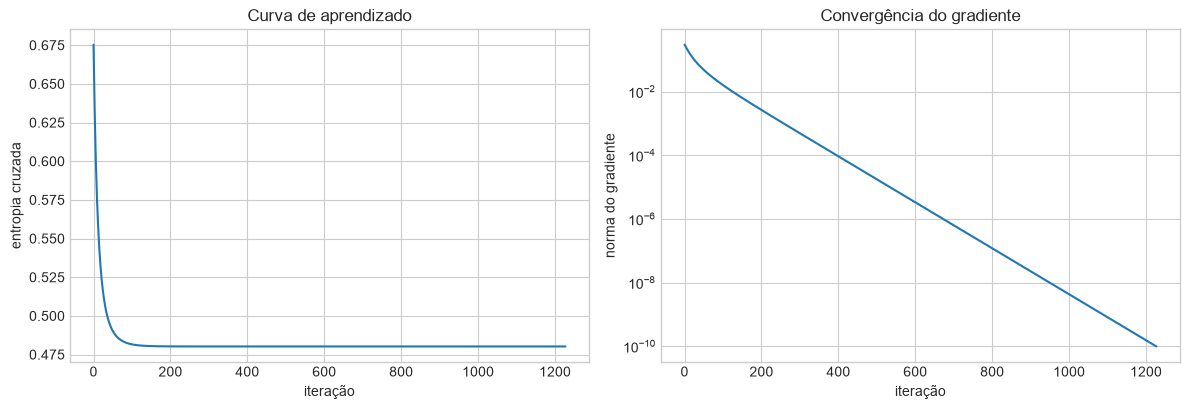

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(history["loss"])
axes[0].set(xlabel="iteração", ylabel="entropia cruzada", title="Curva de aprendizado")
axes[1].semilogy(history["grad_norm"])
axes[1].set(xlabel="iteração", ylabel="norma do gradiente", title="Convergência do gradiente")
plt.tight_layout()
plt.show()

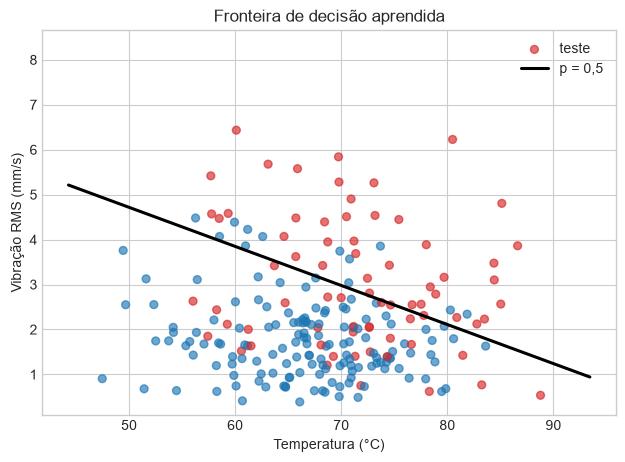

In [16]:
# Fronteira beta0 + beta1*x1_pad + beta2*x2_pad = 0, correspondente a p=0,5.
temp_grade = np.linspace(X[:, 0].min(), X[:, 0].max(), 250)
temp_s = (temp_grade - mean_train[0]) / scale_train[0]
vib_s_fronteira = -(beta_gd[0] + beta_gd[1] * temp_s) / beta_gd[2]
vib_fronteira = vib_s_fronteira * scale_train[1] + mean_train[1]

plt.figure(figsize=(7.4, 5.0))
plt.scatter(X_test[:, 0], X_test[:, 1], c=np.where(y_test == 1, "tab:red", "tab:blue"),
            alpha=0.65, s=32, label="teste")
plt.plot(temp_grade, vib_fronteira, color="black", linewidth=2.2, label="p = 0,5")
plt.ylim(X[:, 1].min() - 0.2, X[:, 1].max() + 0.2)
plt.xlabel("Temperatura (°C)")
plt.ylabel("Vibração RMS (mm/s)")
plt.title("Fronteira de decisão aprendida")
plt.legend()
plt.show()

## 12. Da probabilidade à decisão

Com limiar $t$, classificamos como falha quando $p\ge t$. O limiar $0{,}5$ não é uma lei: ele apenas
trata os dois lados de forma simétrica. Em manutenção, perder uma falha pode custar muito mais que
realizar uma inspeção desnecessária.

In [18]:
def confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return tn, fp, fn, tp


def classification_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_counts(y_true, y_pred)
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }


p_test = predict_proba(Xt_test, beta_gd)
pred_05 = (p_test >= 0.5).astype(int)
metricas_05 = classification_metrics(y_test, pred_05)
print(pd.Series(metricas_05).round(4))
print("Log loss no teste:", binary_cross_entropy(y_test, p_test).round(6))

accuracy       0.8044
precision      0.7736
recall         0.5616
f1             0.6508
tn           140.0000
fp            12.0000
fn            32.0000
tp            41.0000
dtype: float64
Log loss no teste: 0.45139


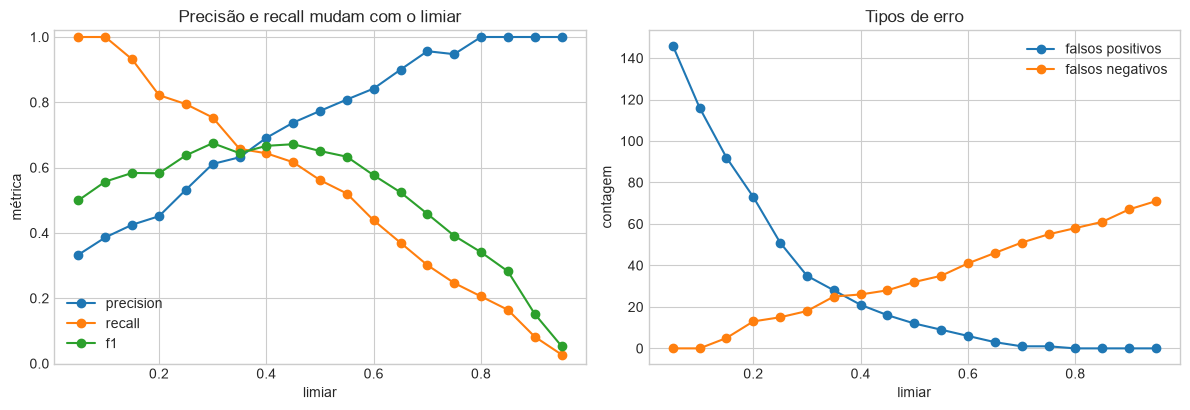

In [19]:
limiares = np.linspace(0.05, 0.95, 19)
linhas = []
for t in limiares:
    m = classification_metrics(y_test, (p_test >= t).astype(int))
    linhas.append({"threshold": t, **m})
curva_limiar = pd.DataFrame(linhas)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for metrica in ["precision", "recall", "f1"]:
    axes[0].plot(curva_limiar["threshold"], curva_limiar[metrica], marker="o", label=metrica)
axes[0].set(xlabel="limiar", ylabel="métrica", ylim=(0, 1.02), title="Precisão e recall mudam com o limiar")
axes[0].legend()

axes[1].plot(curva_limiar["threshold"], curva_limiar["fp"], marker="o", label="falsos positivos")
axes[1].plot(curva_limiar["threshold"], curva_limiar["fn"], marker="o", label="falsos negativos")
axes[1].set(xlabel="limiar", ylabel="contagem", title="Tipos de erro")
axes[1].legend()
plt.tight_layout()
plt.show()

## Exercício 3 — Limiar orientado ao custo

Considere custo de $R\$ 500$ por falso positivo e $R\$ 12.000$ por falso negativo.

1. calcule o custo total para cada limiar da grade anterior;
2. escolha o limiar de menor custo;
3. compare-o com $0{,}5$ em custo, precisão e recall;
4. escreva uma recomendação de até seis linhas para a equipe de manutenção.

**Entregável:** tabela ou gráfico, limiar escolhido e recomendação.

In [ ]:
# =============================================================================
# ✅ RESPOSTA — EXERCÍCIO 3 · itens 1, 2 e 3
# =============================================================================
CUSTO_FP = 500        # inspeção desnecessária
CUSTO_FN = 12_000     # falha não detectada

# 1) custo total de cada limiar da grade
curva_limiar["custo"] = CUSTO_FP * curva_limiar["fp"] + CUSTO_FN * curva_limiar["fn"]
curva_limiar["custo_por_motor"] = curva_limiar["custo"] / len(y_test)
curva_limiar["inspecoes"] = curva_limiar["tp"] + curva_limiar["fp"]

colunas = ["threshold", "precision", "recall", "f1", "fp", "fn", "inspecoes", "custo", "custo_por_motor"]
print(f"Custo de cada limiar (conjunto de teste, n = {len(y_test)} motores, {int(y_test.sum())} falhas reais)")
print(curva_limiar[colunas].round(4).to_string(index=False))

# 2) limiar de menor custo
i_melhor = curva_limiar["custo"].idxmin()
melhor = curva_limiar.loc[i_melhor]
linha_05 = curva_limiar.loc[np.isclose(curva_limiar["threshold"], 0.5)].iloc[0]

# 3) comparação com o limiar 0,5
print("\n" + "=" * 70)
comparacao = pd.DataFrame({
    "limiar 0,50 (padrão)": [linha_05["threshold"], linha_05["precision"], linha_05["recall"],
                             linha_05["fp"], linha_05["fn"], linha_05["inspecoes"], linha_05["custo"]],
    "limiar de menor custo": [melhor["threshold"], melhor["precision"], melhor["recall"],
                              melhor["fp"], melhor["fn"], melhor["inspecoes"], melhor["custo"]],
}, index=["limiar", "precisão", "recall", "falsos positivos", "falsos negativos",
          "inspeções emitidas", "custo total (R$)"])
print(comparacao.round(4).to_string())
print(f"\neconomia: R$ {linha_05['custo'] - melhor['custo']:,.0f} "
      f"({1 - melhor['custo'] / linha_05['custo']:.1%} do custo do limiar 0,5)")

# Referências obrigatórias: os dois extremos triviais
custo_nunca = CUSTO_FN * int(y_test.sum())
custo_sempre = CUSTO_FP * int((y_test == 0).sum())
print("\nBaselines (sem modelo nenhum):")
print(f"   nunca inspecionar : R$ {custo_nunca:>9,.0f}  (R$ {custo_nunca / len(y_test):7.2f} por motor)")
print(f"   inspecionar tudo  : R$ {custo_sempre:>9,.0f}  (R$ {custo_sempre / len(y_test):7.2f} por motor)")
print(f"   modelo em t=0,50  : R$ {linha_05['custo']:>9,.0f}  (R$ {linha_05['custo_por_motor']:7.2f} por motor)"
      "   <- PIOR que inspecionar tudo")
print(f"   modelo no melhor t: R$ {melhor['custo']:>9,.0f}  (R$ {melhor['custo_por_motor']:7.2f} por motor)")

# Limiar teoricamente ótimo: alarmar quando P(falha) * C_FN > (1 - P(falha)) * C_FP
t_bayes = CUSTO_FP / (CUSTO_FP + CUSTO_FN)
print(f"\nLimiar teórico (decisão de Bayes) = C_FP / (C_FP + C_FN) = {t_bayes:.4f}")

# Cuidado metodológico: escolher o limiar no TESTE é vazamento. Refazendo no TREINO:
p_train = predict_proba(Xt_train, beta_gd)
grade_fina = np.round(np.arange(0.01, 1.00, 0.01), 2)
custo_treino = np.array([
    CUSTO_FP * confusion_counts(y_train, (p_train >= t).astype(int))[1]
    + CUSTO_FN * confusion_counts(y_train, (p_train >= t).astype(int))[2]
    for t in grade_fina
])
t_honesto = grade_fina[custo_treino.argmin()]
m_honesto = classification_metrics(y_test, (p_test >= t_honesto).astype(int))
custo_honesto = CUSTO_FP * m_honesto["fp"] + CUSTO_FN * m_honesto["fn"]
print(f"\nLimiar escolhido no TREINO (procedimento sem vazamento): t = {t_honesto:.2f}")
print(f"   aplicado ao teste -> custo R$ {custo_honesto:,} "
      f"(R$ {custo_honesto / len(y_test):.2f}/motor), recall {m_honesto['recall']:.4f}, "
      f"precisão {m_honesto['precision']:.4f}")
print(f"   diferença para o 'melhor' medido no próprio teste: R$ {custo_honesto - melhor['custo']:,.0f} "
      "-> essa é a parcela otimista de se escolher o limiar olhando o teste.")

# gráficos de apoio
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

axes[0].plot(curva_limiar["threshold"], curva_limiar["custo"] / 1000, marker="o", color="tab:purple")
axes[0].axvline(melhor["threshold"], color="tab:green", linestyle="--",
                label=f"menor custo: t = {melhor['threshold']:.2f}")
axes[0].axvline(0.5, color="tab:red", linestyle="--", label="t = 0,50 (padrão)")
axes[0].axhline(custo_sempre / 1000, color="gray", linestyle=":", label="inspecionar tudo")
axes[0].set(xlabel="limiar", ylabel="custo total (R$ mil)",
            title="Custo total em função do limiar")
axes[0].legend(fontsize=8)

largura = 0.035
axes[1].bar(curva_limiar["threshold"], CUSTO_FP * curva_limiar["fp"] / 1000,
            width=largura, label=f"custo dos FP (R$ {CUSTO_FP})")
axes[1].bar(curva_limiar["threshold"], CUSTO_FN * curva_limiar["fn"] / 1000,
            width=largura, bottom=CUSTO_FP * curva_limiar["fp"] / 1000,
            label=f"custo dos FN (R$ {CUSTO_FN:,})")
axes[1].axvline(melhor["threshold"], color="black", linestyle="--")
axes[1].set(xlabel="limiar", ylabel="custo (R$ mil)",
            title="De onde vem o custo: o FN domina quase toda a faixa")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

---

## ✅ RESPOSTA — Exercício 3 (Limiar orientado ao custo)

> Custos: **R\$ 500** por falso positivo (inspeção desnecessária) e **R\$ 12.000** por falso negativo (falha não detectada). Avaliação sobre os 225 motores do conjunto de teste (73 falhas reais).

### 1. Custo de cada limiar da grade

| limiar | precisão | recall | FP | FN | inspeções | custo total |
|--:|--:|--:|--:|--:|--:|--:|
| 0,05 | 0,333 | 1,000 | 146 | 0 | 219 | R\$ 73.000 |
| **0,10** | **0,386** | **1,000** | **116** | **0** | **189** | **R\$ 58.000** ← mínimo |
| 0,15 | 0,425 | 0,932 | 92 | 5 | 160 | R\$ 106.000 |
| 0,20 | 0,451 | 0,822 | 73 | 13 | 133 | R\$ 192.500 |
| 0,25 | 0,532 | 0,795 | 51 | 15 | 109 | R\$ 205.500 |
| 0,30 | 0,611 | 0,753 | 35 | 18 | 90 | R\$ 233.500 |
| 0,40 | 0,691 | 0,644 | 21 | 26 | 68 | R\$ 322.500 |
| **0,50** | **0,774** | **0,562** | **12** | **32** | **53** | **R\$ 390.000** |
| 0,70 | 0,957 | 0,301 | 1 | 51 | 23 | R\$ 612.500 |
| 0,95 | 1,000 | 0,027 | 0 | 71 | 2 | R\$ 852.000 |

*(tabela completa com os 19 limiares na saída da célula acima)*

### 2. Limiar de menor custo: $t = 0{,}10$

### 3. Comparação com o limiar padrão

| | $t = 0{,}50$ (padrão) | $t = 0{,}10$ (menor custo) | variação |
|:--|--:|--:|:--|
| precisão | 0,7736 | 0,3862 | **piora** (mais alarmes em vão) |
| recall | 0,5616 | **1,0000** | **melhora**: nenhuma falha escapa |
| falsos positivos | 12 | 116 | +104 inspeções desnecessárias |
| falsos negativos | 32 | **0** | −32 falhas não detectadas |
| custo total | R\$ 390.000 | **R\$ 58.000** | **−R\$ 332.000 (−85,1%)** |
| custo por motor | R\$ 1.733,33 | R\$ 257,78 | |

O limiar 0,5 é o que **maximiza a acurácia**, não o que minimiza o prejuízo. Como um falso negativo custa **24 vezes** um falso positivo, trocar 32 falhas perdidas por 104 inspeções a mais é um negócio excelente: gasta-se R\$ 52.000 em inspeções para evitar R\$ 384.000 em paradas. A precisão cai de 0,77 para 0,39 — e isso é correto, porque precisão não é o objetivo: **o objetivo está em reais**.

Vale registrar o valor teórico: a decisão de Bayes manda alarmar quando $P(\text{falha}\mid x)\cdot C_{FN} > (1-P)\cdot C_{FP}$, ou seja quando

$$P(\text{falha}\mid x) \;>\; \frac{C_{FP}}{C_{FP}+C_{FN}} = \frac{500}{12\,500} = 0{,}04 .$$

O mínimo empírico ficou em 0,10, e não em 0,04, porque nesta amostra de teste **nenhuma falha recebeu probabilidade abaixo de 0,10** (a faixa $p \le 0{,}1$ contém 36 motores, todos normais). Com 225 observações, o ponto exato do mínimo é ruidoso — a curva de custo é praticamente plana entre 0,05 e 0,10.

### ⚠️ Ressalva metodológica (importante)

Os R\$ 58.000 são uma estimativa **otimista**: o limiar foi escolhido olhando o próprio conjunto de teste, o que é a forma mais comum de vazamento em ajuste de hiperparâmetro. Refazendo a escolha **no treino** e só então aplicando ao teste, obtém-se $t = 0{,}04$ (exatamente o valor teórico) e custo de **R\$ 73.500** no teste. É esse o número que eu levaria para a gerência.

### 4. Recomendação à equipe de manutenção (seis linhas)

> 1. **Baixem o limiar de alarme de 0,50 para 0,05–0,10.** O padrão 0,50 custa R\$ 390.000 no período avaliado; na faixa recomendada o custo cai para cerca de R\$ 58.000–73.500 — de 85% a 81% de redução.
> 2. **O sistema passará a sinalizar ~84% da frota** (189 de 225 motores) e a errar para o lado seguro: zero falhas não detectadas, ao preço de inspeções em motores sadios.
> 3. **Verifiquem a capacidade de inspeção antes de adotar.** Se a equipe não consegue inspecionar 8 de cada 10 motores por turno, o limiar ótimo muda: o custo real inclui a fila de manutenção e a perda de credibilidade do alarme, que não estão nos R\$ 500.
> 4. **Comparem sempre com o extremo trivial:** "inspecionar tudo" custa R\$ 76.000 e não exige modelo nenhum. O modelo no melhor limiar economiza apenas R\$ 18.000 (24%) sobre isso — e no limiar 0,50 é **cinco vezes pior** que inspecionar tudo.
> 5. **O ganho relevante virá de um modelo melhor, não de um limiar melhor:** com temperatura e vibração apenas, as classes se sobrepõem demais (log loss de 0,451, recall de 0,56 em $t=0{,}5$). Um sensor adicional muda esse teto; o limiar apenas redistribui os erros.
> 6. **Revalidem a cada trimestre**, refazendo a escolha do limiar em dados de treino separados e recalculando os custos unitários com o setor financeiro — R\$ 500 e R\$ 12.000 são premissas do modelo, e é delas que a recomendação inteira depende.

---

## 13. Comparação com scikit-learn

A comparação verifica se nossa implementação converge para a mesma solução de uma biblioteca
consolidada. Desativamos a regularização (`penalty=None`) porque nosso modelo atual também não a usa.

In [21]:
# C infinito desativa, na prática, a penalização L2 nas versões atuais do scikit-learn.
modelo_sk = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=10_000)
modelo_sk.fit(X_train_s, y_train)

beta_sk = np.r_[modelo_sk.intercept_[0], modelo_sk.coef_[0]]
p_sk = modelo_sk.predict_proba(X_test_s)[:, 1]

comparacao_beta = pd.DataFrame({
    "parametro": ["intercepto", *nomes],
    "NumPy_GD": beta_gd,
    "scikit_learn": beta_sk,
    "diferenca_abs": np.abs(beta_gd - beta_sk),
})
print(comparacao_beta.round(6))
print("\nMaior diferença nas probabilidades de teste:", np.max(np.abs(p_test - p_sk)))
print("Log loss sklearn:", round(log_loss(y_test, p_sk), 6))

       parametro  NumPy_GD  scikit_learn  diferenca_abs
0     intercepto -0.921128     -0.921128       0.000000
1  temperatura_C  0.657966      0.658007       0.000041
2  vibracao_mm_s  1.298682      1.298672       0.000010

Maior diferença nas probabilidades de teste: 2.6436250615158308e-05
Log loss sklearn: 0.451389


### O que significa coincidir?

As implementações não precisam produzir bits idênticos: usam critérios de parada e algoritmos de
otimização diferentes. Porém, coeficientes, probabilidades e custo devem ser numericamente próximos.
Uma divergência grande sugere erro na função de custo, no gradiente, na padronização ou no tratamento
do intercepto.

### Nota prática — Desbalanceamento

Se apenas 2% dos equipamentos falham, prever sempre “normal” produz 98% de acurácia. O exemplo abaixo
mostra por que toda avaliação deve incluir baseline, matriz de confusão, precisão, recall e F1. Não há
exercício adicional nesta seção.

In [22]:
rng = np.random.default_rng(SEED)
y_raro = np.zeros(1000, dtype=int)
y_raro[rng.choice(1000, size=20, replace=False)] = 1
pred_tudo_normal = np.zeros_like(y_raro)
print(pd.Series(classification_metrics(y_raro, pred_tudo_normal)).round(4))

accuracy       0.98
precision      0.00
recall         0.00
f1             0.00
tn           980.00
fp             0.00
fn            20.00
tp             0.00
dtype: float64


# Referências

**Bibliografia da disciplina**

- RUSSELL, S. J.; NORVIG, P. *Inteligência artificial: uma abordagem moderna*. Rio de Janeiro:
  GEN LTC, 2022. Cap. 19, seção sobre regressão logística.
- FACELI, K.; LORENA, A. C.; GAMA, J.; CARVALHO, A. C. P. L. F.; ALMEIDA, T. A.
  *Inteligência artificial: uma abordagem de aprendizado de máquina*. Rio de Janeiro: LTC, 2025.

**Documentação oficial**

- NumPy — https://numpy.org/doc/stable/
- scikit-learn, `LogisticRegression` —
  https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- scikit-learn, métricas de classificação —
  https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics
- scikit-learn, *Common pitfalls* —
  https://scikit-learn.org/stable/common_pitfalls.html

**Leitura complementar**

- HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. *The Elements of Statistical Learning*. 2. ed.
  Springer, 2009. Cap. 4.